In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
from pathlib import Path
import scipy
import os
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import ImageFolder
import torchvision.transforms as T

print("Done with library declaration, Current version of Tensorflow is: ", tf.__version__)

Done with library declaration, Current version of Tensorflow is:  2.20.0


In [98]:
# Path to the dataset folder
data_dir = r"C:\Users\Isra\Downloads\trash_dataset2\Garbage_classification"
PATH_TRAIN = r"C:\Users\Isra\Downloads\trash_dataset2\processed"
PATH_VAL = r"C:\Users\Isra\Downloads\trash_dataset2\validation"
PATH_TEST = r"C:\Users\Isra\Downloads\trash_dataset2\test"

class_names = ['cardboard', 'glass', 'metal','paper','plastic','trash','battery','biological']
imagepath_cardboard = r"C:\Users\Isra\Downloads\trash_dataset2\Garbage classification\cardboard"
graypath_cardboard = r"C:\Users\Isra\Downloads\trash_dataset2\Garbage_processed\cardboard"


In [3]:
import os
from PIL import Image


def process_images(input_path, output_path, target_size=(224, 224)):  
    try:
        with Image.open(input_path) as im:
            # Handle transparency
            if im.mode in ('RGBA', 'LA', 'P'):
                background = Image.new('RGB', im.size, (255, 255, 255))
                if im.mode == 'RGBA':
                    background.paste(im, mask=im.split()[-1])
                else:
                    background.paste(im)
                img = background
            else:
                img = im.convert('RGB')
            
            img = img.resize(target_size, Image.LANCZOS)
            # PAS DE CONVERSION EN GRIS - garder RGB
            img.save(output_path, "JPEG", quality=95)
    except Exception as e:
        raise RuntimeError(f"Failed to process {input_path}: {e}")


def process_categories(input_base_dir, output_base_dir, categories=None, target_size=(128, 128)):
    """
    Process image categories (resize + grayscale + convert to JPEG).
    If categories=None, process all categories.
    """
    os.makedirs(output_base_dir, exist_ok=True)

    if categories is None:
        categories = [d for d in os.listdir(input_base_dir)
                      if os.path.isdir(os.path.join(input_base_dir, d))]

    print(f"Processing categories: {categories}")

    valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.tif', '.webp')
    total_processed = 0
    total_errors = 0

    for category in categories:
        input_category_path = os.path.join(input_base_dir, category)
        output_category_path = os.path.join(output_base_dir, category)

        if not os.path.exists(input_category_path):
            print(f"⚠️ Warning: {category} does not exist in dataset. Skipping.")
            continue

        os.makedirs(output_category_path, exist_ok=True)

        try:
            file_listing = os.listdir(input_category_path)
        except Exception as e:
            print(f"Error accessing {input_category_path}: {e}")
            continue

        processed_count = 0
        error_count = 0

        for file in file_listing:
            if not file.lower().endswith(valid_extensions) or file.startswith('.'):
                continue

            input_path = os.path.join(input_category_path, file)
            output_path = os.path.join(output_category_path, file)

            try:
                process_images(input_path, output_path, target_size)
                processed_count += 1
                total_processed += 1

                if processed_count % 50 == 0:
                    print(f"  {category}: {processed_count} done...")

            except Exception as e:
                error_count += 1
                total_errors += 1
                print(f"❌ Error processing {file} in {category}: {e}")
                with open("processing_errors.log", "a") as log:
                    log.write(f"{category}/{file}: {e}\n")

        print(f"✅ Category '{category}': {processed_count} images processed, {error_count} errors.")

    print(f"\n🎉 All done! Total processed: {total_processed}, Total errors: {total_errors}")
    print(f"Processed dataset saved in: {output_base_dir}")

input_base_dir = data_dir
output_base_dir = PATH_TRAIN
# Process ALL categories 
process_categories(input_base_dir, output_base_dir, target_size=(224, 224))



Processing categories: ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
  battery: 50 done...
  battery: 100 done...
  battery: 150 done...
  battery: 200 done...
  battery: 250 done...
  battery: 300 done...
  battery: 350 done...
  battery: 400 done...
  battery: 450 done...
  battery: 500 done...
  battery: 550 done...
  battery: 600 done...
  battery: 650 done...
  battery: 700 done...
  battery: 750 done...
  battery: 800 done...
✅ Category 'battery': 800 images processed, 0 errors.
  biological: 50 done...
  biological: 100 done...
  biological: 150 done...
  biological: 200 done...
  biological: 250 done...
  biological: 300 done...
  biological: 350 done...
  biological: 400 done...
  biological: 450 done...
  biological: 500 done...
  biological: 550 done...
  biological: 600 done...
  biological: 650 done...
  biological: 700 done...
  biological: 750 done...
  biological: 800 done...
✅ Category 'biological': 800 images processed, 0 errors

In [4]:
import os
import shutil
from sklearn.model_selection import train_test_split

def create_validation_set(source_dir, validation_ratio=0.2):

    
    # Create validation directory next to your source directory
    base_dir = os.path.dirname(source_dir)
    val_dir = os.path.join(base_dir, "validation")
    os.makedirs(val_dir, exist_ok=True)
    
    print(f"Creating validation set in: {val_dir}")
    print(f"Using {validation_ratio*100}% of data for validation")
    
    # Get all categories
    categories = [d for d in os.listdir(source_dir) 
                 if os.path.isdir(os.path.join(source_dir, d))]
    
    total_moved = 0
    
    for category in categories:
        source_category_dir = os.path.join(source_dir, category)
        val_category_dir = os.path.join(val_dir, category)
        os.makedirs(val_category_dir, exist_ok=True)
        
        # Get all image files
        images = [f for f in os.listdir(source_category_dir) 
                 if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
        
        # Split images: keep (1-ratio) for training, move ratio to validation
        keep_files, move_files = train_test_split(images, test_size=validation_ratio, random_state=42)
        
        # Move files to validation set
        for file in move_files:
            src = os.path.join(source_category_dir, file)
            dst = os.path.join(val_category_dir, file)
            shutil.move(src, dst)
            total_moved += 1
        
        print(f"{category}: moved {len(move_files)} to validation, kept {len(keep_files)} for training")
    
    print(f"Total files moved to validation: {total_moved}")
    return val_dir

# Usage:
source_dir = PATH_TRAIN
validation_dir = create_validation_set(source_dir, validation_ratio=0.2)

print(f"Your training directory: {source_dir}")
print(f"Your new validation directory: {validation_dir}")

Creating validation set in: C:\Users\Isra\Downloads\trash_dataset2\validation
Using 20.0% of data for validation
battery: moved 160 to validation, kept 640 for training
biological: moved 160 to validation, kept 640 for training
cardboard: moved 160 to validation, kept 640 for training
glass: moved 160 to validation, kept 640 for training
metal: moved 160 to validation, kept 640 for training
paper: moved 160 to validation, kept 640 for training
plastic: moved 160 to validation, kept 640 for training
trash: moved 160 to validation, kept 640 for training
Total files moved to validation: 1280
Your training directory: C:\Users\Isra\Downloads\trash_dataset2\processed
Your new validation directory: C:\Users\Isra\Downloads\trash_dataset2\validation


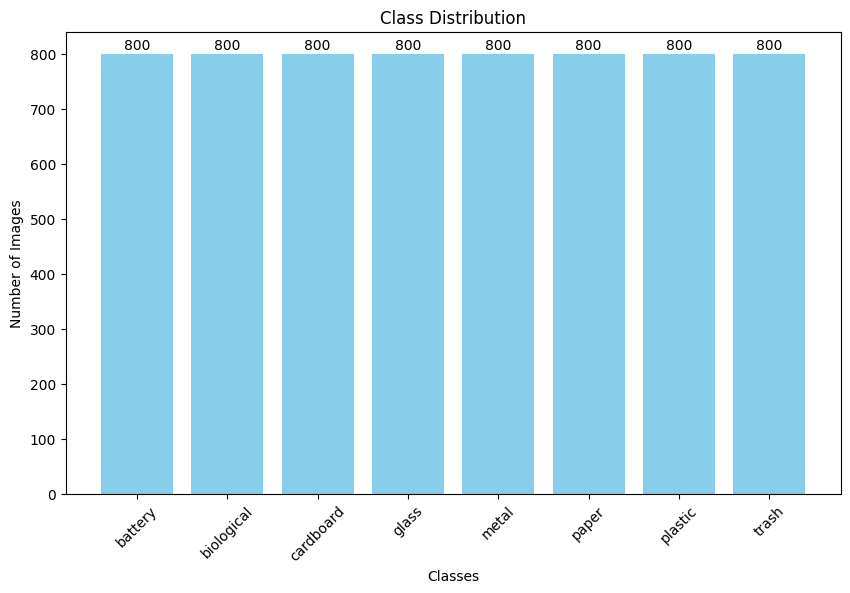

In [5]:
import os
import matplotlib.pyplot as plt



# Get class names (subfolder names)
classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
classes.sort()  

# Count images in each class
counts = []
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    num_images = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    counts.append(num_images)

# Plot bar chart
plt.figure(figsize=(10,6))
plt.bar(classes, counts, color='skyblue')
plt.title('Class Distribution')
plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)
for i, count in enumerate(counts):
    plt.text(i, count + 2, str(count), ha='center', va='bottom')
plt.show()

In [96]:
def create_data_generators_weighted(train_dir, val_dir, target_size=(224, 224), batch_size=16):
    # Define aggressive augmentation for battery
    aggressive_aug = ImageDataGenerator(
        rescale=1.0/255,
        rotation_range=40,
        width_shift_range=0.25,
        height_shift_range=0.25,
        shear_range=0.25,
        zoom_range=0.25,
        horizontal_flip=True,
        vertical_flip=True,
        brightness_range=[0.7, 1.3],
        channel_shift_range=30,
        fill_mode='nearest'
    )

    # Standard augmentation for other classes
    standard_aug = ImageDataGenerator(
        rescale=1.0/255,
        rotation_range=30,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        vertical_flip=True,
        brightness_range=[0.8, 1.2],
        fill_mode='nearest'
    )

    # Validation generator (no augmentation)
    val_datagen = ImageDataGenerator(rescale=1.0/255)

    # Create separate generators
    battery_gen = aggressive_aug.flow_from_directory(
        os.path.join(train_dir, 'battery'),
        target_size=target_size,
        batch_size=batch_size,
        class_mode='categorical',
        color_mode='rgb',
        shuffle=True,
        seed=42
    )

    other_gen = standard_aug.flow_from_directory(
        train_dir,
        target_size=target_size,
        batch_size=batch_size,
        class_mode='categorical',
        color_mode='rgb',
        shuffle=True,
        seed=42
    )

    val_gen = val_datagen.flow_from_directory(
        val_dir,
        target_size=target_size,
        batch_size=batch_size,
        class_mode='categorical',
        color_mode='rgb',
        shuffle=False
    )

    return other_gen, val_gen, len(other_gen), len(val_gen)


In [99]:
train_gen, val_gen, train_steps, val_steps = create_data_generators_weighted(PATH_TRAIN, PATH_VAL)


Found 0 images belonging to 0 classes.
Found 5120 images belonging to 8 classes.
Found 2771 images belonging to 8 classes.


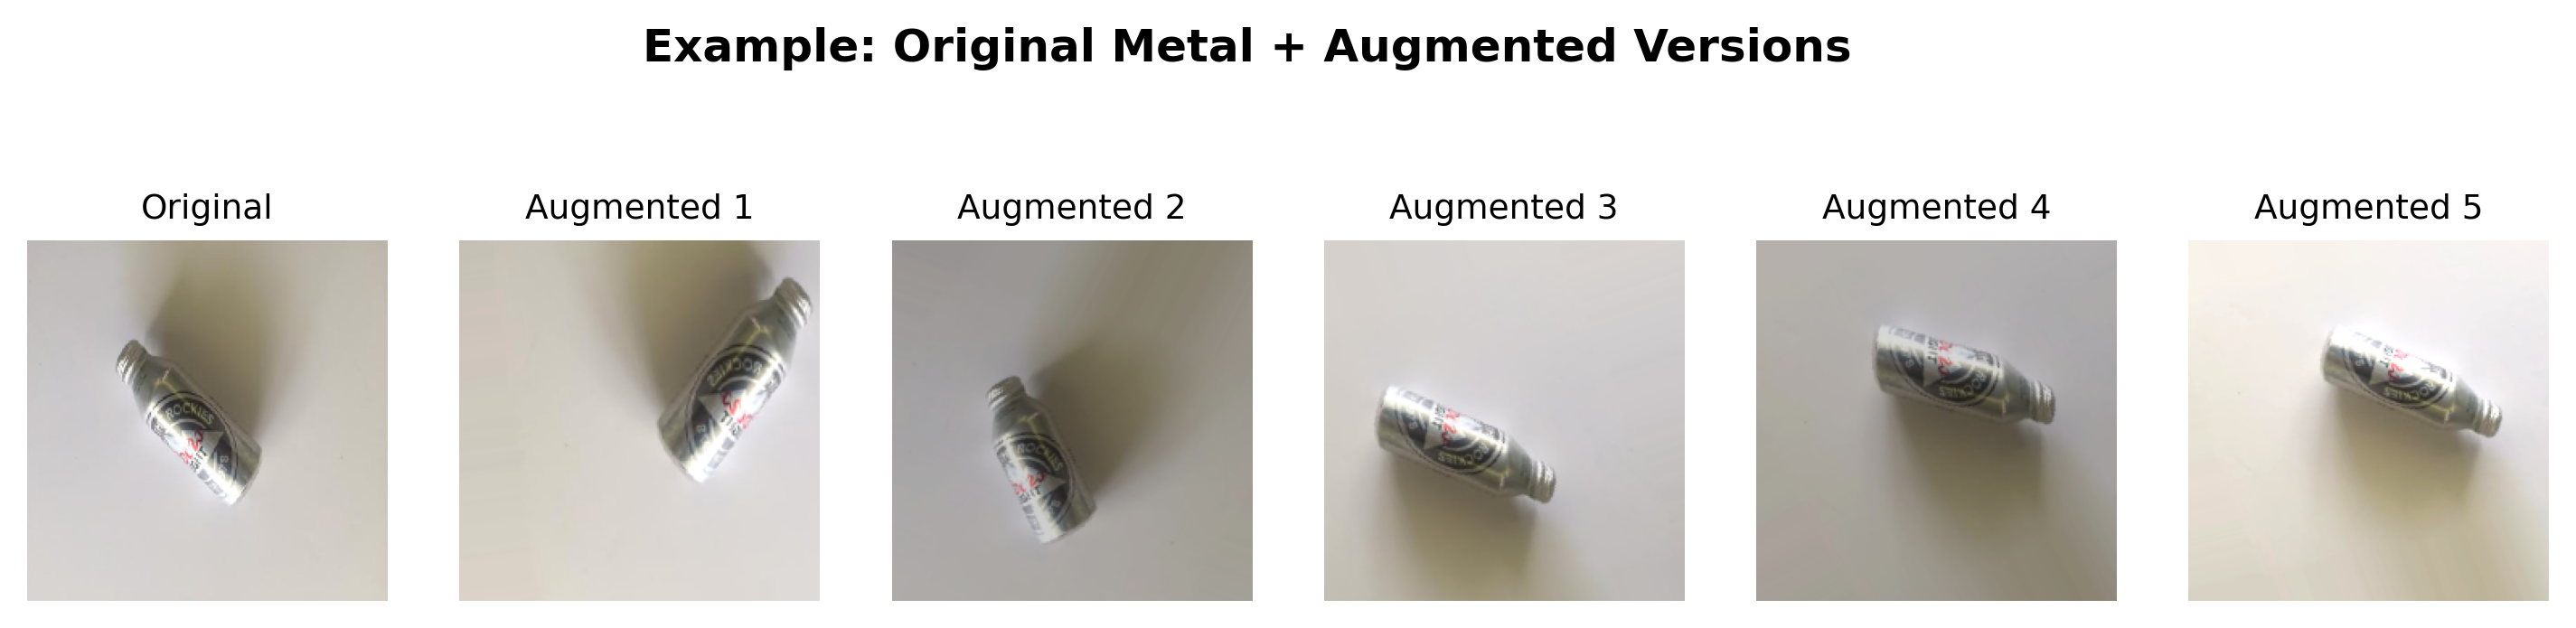

In [113]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
import numpy as np
import os

# --------------------------
# Pick your example image
# --------------------------
example_class = "metal"  
example_image_filename = r"C:\Users\Isra\Downloads\trash_dataset2\Garbage_classification\metal\metal81.jpg"  
example_image_path = os.path.join(PATH_TRAIN, example_class, example_image_filename)

# Load and preprocess the image
img = load_img(example_image_path, target_size=(224, 224))
x = img_to_array(img)
x = x.reshape((1,) + x.shape)  

# --------------------------
# Standard augmentation (from your generator)
# --------------------------
standard_aug = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# --------------------------
# Plot original + 5 augmented versions
# --------------------------
plt.figure(figsize=(12, 3))

# Original first
plt.subplot(1, 6, 1)
plt.imshow(x[0]/255.0)  # normalize for plotting
plt.axis('off')
plt.title("Original", fontsize=9)

# Generate 5 augmented images
i = 2
for batch in standard_aug.flow(x, batch_size=1, seed=42):
    aug_img = batch[0]
    plt.subplot(1, 6, i)
    plt.imshow(aug_img)
    plt.axis('off')
    plt.title(f"Augmented {i-1}", fontsize=9)
    i += 1
    if i > 6:  # only 5 augmented versions
        break

plt.suptitle(f"Example: Original {example_class.capitalize()} + Augmented Versions", fontsize=12, fontweight='bold')
plt.show()


Batch shape: (16, 224, 224, 3)
Labels shape: (16, 8)


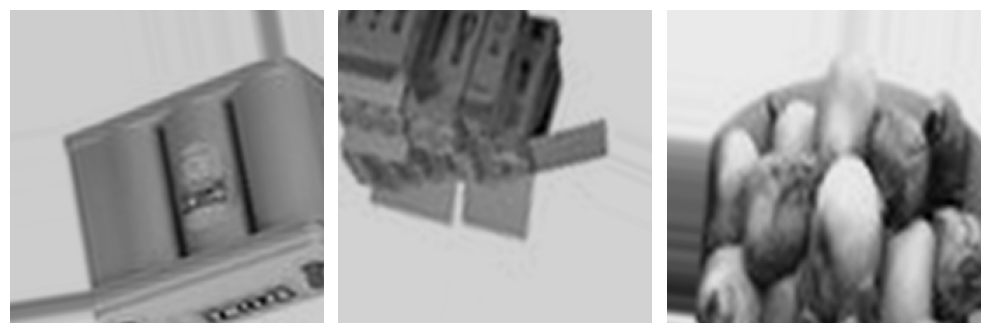

In [8]:

# Obtenir un batch d'images d'entraînement
sample_training_images, sample_training_labels = next(train_gen)
print(f"Batch shape: {sample_training_images.shape}")
print(f"Labels shape: {sample_training_labels.shape}")

# PUIS exécuter plotImages
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 3, figsize=(10,10))
    axes = axes.flatten()
    for img, ax in zip(images_arr, axes):
        ax.imshow(img)  # Pas besoin de ,cmap='gray' pour RGB
        ax.axis('off')
    plt.tight_layout()
    plt.show()

plotImages(sample_training_images[:3])

In [9]:
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
import tensorflow as tf

def create_enhanced_model(num_classes):
    model = Sequential()
    
    # Block 1
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)))  # ✅ 3 channels
    model.add(BatchNormalization())
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(2, 2))
    model.add(Dropout(0.25))
    
    # Block 2  
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(2, 2))
    model.add(Dropout(0.25))
    
    # Block 3
    model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(2, 2))
    model.add(Dropout(0.25))
    
    # Classifier
    model.add(Flatten())
    model.add(Dense(512, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.5))
    
    model.add(Dense(256, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.3))
    
    model.add(Dense(num_classes, activation='softmax'))
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model

# Example usage
# num_classes = len(train_gen.class_indices)  # if you’re using ImageDataGenerator
# model = create_enhanced_model(num_classes)
# model.summary()


In [10]:
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, BatchNormalization, Dropout, Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Sequential


def create_transfer_learning_model_resnet(num_classes=8):
    base_model = ResNet50V2(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    
    base_model.trainable = False
    
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        BatchNormalization(),
        Dropout(0.5),
        Dense(512, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model, base_model

model, base_model = create_transfer_learning_model_resnet()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,758,536 (94.45 MB)

 Trainable params: 1,188,104 (4.53 MB)

 Non-trainable params: 23,570,432 (89.91 MB)

In [11]:
model.compile(optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,758,536 (94.45 MB)

 Trainable params: 1,188,104 (4.53 MB)

 Non-trainable params: 23,570,432 (89.91 MB)

C:\Users\Isra\anaconda3\pole projet\envs\tf\lib\site-packages\visualkeras\layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


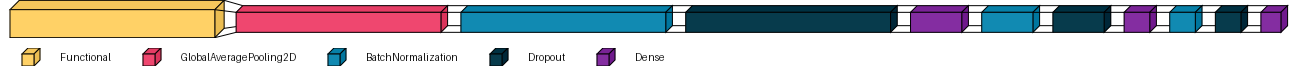

In [13]:
import visualkeras
visualkeras.layered_view(model, legend=True, spacing=20)

In [14]:
from collections import defaultdict

class DatasetCounter:
    def __init__(self, categories):
        self.categories = categories
        self.train_dir = PATH_TRAIN
        self.test_dir = PATH_TEST
        self.train_counts = defaultdict(int)
        self.test_counts = defaultdict(int)
    
    def count_files(self, directory):
        """Count files in all category directories"""
        counts = {}
        for category in self.categories:
            category_path = os.path.join(directory, category)
            if os.path.exists(category_path):
                try:
                    files = [f for f in os.listdir(category_path) 
                            if os.path.isfile(os.path.join(category_path, f)) and not f.startswith('.')]
                    counts[category] = len(files)
                except Exception as e:
                    print(f"Error counting {category}: {str(e)}")
                    counts[category] = 0
            else:
                counts[category] = 0
        return counts
    
    def generate_report(self):
        """Generate a comprehensive report"""
        self.train_counts = self.count_files(self.train_dir)
        self.test_counts = self.count_files(self.test_dir)
        
        total_train = sum(self.train_counts.values())
        total_test = sum(self.test_counts.values())
        
        print("=" * 50)
        print("DATASET ANALYSIS REPORT")
        print("=" * 50)
        print(f"{'Category':<12} {'Train':<8} {'Test':<8} {'Total':<8}")
        print("-" * 50)
        
        for category in self.categories:
            train_count = self.train_counts[category]
            test_count = self.test_counts[category]
            total = train_count + test_count
            print(f"{category:<12} {train_count:<8} {test_count:<8} {total:<8}")
        
        print("-" * 50)
        print(f"{'TOTAL':<12} {total_train:<8} {total_test:<8} {total_train + total_test:<8}")
        print("=" * 50)
        
        return self.train_counts, self.test_counts

# Usage
categories = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash','battery','biological']
counter = DatasetCounter(categories)
train_counts, test_counts = counter.generate_report()

DATASET ANALYSIS REPORT
Category     Train    Test     Total   
--------------------------------------------------
cardboard    640      33       673     
glass        640      19       659     
metal        640      11       651     
paper        640      18       658     
plastic      640      12       652     
trash        640      10       650     
battery      640      14       654     
biological   640      8        648     
--------------------------------------------------
TOTAL        5120     125      5245    


In [15]:
def check_data_sanity(train_gen, val_gen):
    """Quick check to ensure data is loaded correctly"""
    import numpy as np

    print("\n=== DATA SANITY CHECK ===")
    
    # Check batch shapes
    x_batch, y_batch = next(train_gen)
    print(f"Training batch - Images shape: {x_batch.shape}")
    print(f"Training batch - Labels shape: {y_batch.shape}")
    print(f"Image value range: [{x_batch.min():.3f}, {x_batch.max():.3f}]")
    
    # Check validation batch
    x_val_batch, y_val_batch = next(val_gen)
    print(f"Validation batch - Images shape: {x_val_batch.shape}")
    
    # Check class distribution
    print(f"\nClass indices: {train_gen.class_indices}")
    
    # Reset generators after checking
    train_gen.on_epoch_end()
    val_gen.on_epoch_end()

check_data_sanity(train_gen, val_gen)




=== DATA SANITY CHECK ===
Training batch - Images shape: (16, 224, 224, 3)
Training batch - Labels shape: (16, 8)
Image value range: [0.000, 1.000]
Validation batch - Images shape: (16, 224, 224, 3)

Class indices: {'battery': 0, 'biological': 1, 'cardboard': 2, 'glass': 3, 'metal': 4, 'paper': 5, 'plastic': 6, 'trash': 7}


In [129]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

def compute_weights(train_gen):
    """Compute class weights for imbalanced data"""
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(train_gen.classes),
        y=train_gen.classes
    )
    return dict(enumerate(class_weights))


In [130]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ✅ Define callbacks inline
callbacks = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=15,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.5,
        patience=8,
        min_lr=1e-7,
        mode='max',
        verbose=1
    ),
    ModelCheckpoint(
        filepath='best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    )
]

# 🧪 Phase 1: Train with frozen backbone
def train_phase1(model, train_gen, val_gen, class_weights, epochs=30, lr=1e-4):
    print("="*60)
    print("PHASE 1: Training with frozen backbone")
    print("="*60)

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=epochs,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )
    return history

# 🔧 Phase 2: Fine-tune with unfrozen backbone
def train_phase2(model, base_model, train_gen, val_gen, class_weights, epochs=50, lr=1e-5):
    print("="*60)
    print("PHASE 2: Fine-tuning with unfrozen backbone")
    print("="*60)

    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=epochs,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )
    return history


In [ ]:
# Compute class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weights = dict(enumerate(class_weights))

# Phase 1
history1 = train_phase1(model, train_gen, val_gen, class_weights)

# Phase 2
history2 = train_phase2(model, base_model, train_gen, val_gen, class_weights)


PHASE 1: Training with frozen backbone


C:\Users\Isra\anaconda3\pole projet\envs\tf\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.3163 - loss: 3.3300
Epoch 1: val_accuracy improved from None to 0.78780, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 186s 555ms/step - accuracy: 0.4498 - loss: 2.8532 - val_accuracy: 0.7878 - val_loss: 1.7997 - learning_rate: 1.0000e-04
Epoch 2/30
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.6309 - loss: 2.2517
Epoch 2: val_accuracy improved from 0.78780 to 0.83869, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 175s 548ms/step - accuracy: 0.6512 - loss: 2.1931 - val_accuracy: 0.8387 - val_loss: 1.5989 - learning_rate: 1.0000e-04
Epoch 3/30
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step - accuracy: 0.6982 - loss: 2.0206
Epoch 3: val_accuracy improved from 0.83869 to 0.86539, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 171s 535ms/step - accuracy: 0.7072 - loss: 1.9928 - val_accuracy: 0.8654 - val_loss: 1.5142 - learning_rate: 1.0000e-04
Epoch 4/30
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.7348 - loss: 1.9143
Epoch 4: val_accuracy improved from 0.86539 to 0.88019, saving model to best_model.h5


... (36 outputs left out)

320/320 ━━━━━━━━━━━━━━━━━━━━ 226s 706ms/step - accuracy: 0.9400 - loss: 0.8955 - val_accuracy: 0.9773 - val_loss: 0.8076 - learning_rate: 1.0000e-05
Epoch 34/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.9507 - loss: 0.8842
Epoch 34: val_accuracy did not improve from 0.97726
320/320 ━━━━━━━━━━━━━━━━━━━━ 223s 695ms/step - accuracy: 0.9525 - loss: 0.8770 - val_accuracy: 0.9765 - val_loss: 0.8057 - learning_rate: 1.0000e-05
Epoch 35/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - accuracy: 0.9415 - loss: 0.8928
Epoch 35: val_accuracy did not improve from 0.97726
320/320 ━━━━━━━━━━━━━━━━━━━━ 227s 709ms/step - accuracy: 0.9428 - loss: 0.8918 - val_accuracy: 0.9773 - val_loss: 0.8006 - learning_rate: 1.0000e-05
Epoch 36/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 562ms/step - accuracy: 0.9537 - loss: 0.8633
Epoch 36: val_accuracy improved from 0.97726 to 0.97943, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 240s 750ms/step - accuracy: 0.9549 - loss: 0.8667 - val_accuracy: 0.9794 - val_loss: 0.7948 - learning_rate: 1.0000e-05
Epoch 37/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.9461 - loss: 0.8765
Epoch 37: val_accuracy did not improve from 0.97943
320/320 ━━━━━━━━━━━━━━━━━━━━ 241s 752ms/step - accuracy: 0.9445 - loss: 0.8832 - val_accuracy: 0.9787 - val_loss: 0.7928 - learning_rate: 1.0000e-05
Epoch 38/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.9600 - loss: 0.8461
Epoch 38: val_accuracy did not improve from 0.97943
320/320 ━━━━━━━━━━━━━━━━━━━━ 227s 708ms/step - accuracy: 0.9518 - loss: 0.8691 - val_accuracy: 0.9762 - val_loss: 0.7916 - learning_rate: 1.0000e-05
Epoch 39/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.9532 - loss: 0.8623
Epoch 39: val_accuracy did not improve from 0.97943
320/320 ━━━━━━━━━━━━━━━━━━━━ 239s 745ms/step - accuracy: 0.9531 - loss: 0.8552 - val_accuracy: 0.9769 - val_loss: 0.7906 - learnin

320/320 ━━━━━━━━━━━━━━━━━━━━ 236s 738ms/step - accuracy: 0.9541 - loss: 0.8518 - val_accuracy: 0.9802 - val_loss: 0.7786 - learning_rate: 1.0000e-05
Epoch 43/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 548ms/step - accuracy: 0.9611 - loss: 0.8254
Epoch 43: val_accuracy improved from 0.98015 to 0.98123, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 239s 748ms/step - accuracy: 0.9596 - loss: 0.8328 - val_accuracy: 0.9812 - val_loss: 0.7733 - learning_rate: 1.0000e-05
Epoch 44/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.9584 - loss: 0.8364
Epoch 44: val_accuracy did not improve from 0.98123
320/320 ━━━━━━━━━━━━━━━━━━━━ 242s 756ms/step - accuracy: 0.9582 - loss: 0.8326 - val_accuracy: 0.9787 - val_loss: 0.7714 - learning_rate: 1.0000e-05
Epoch 45/50
 19/320 ━━━━━━━━━━━━━━━━━━━━ 3:28 694ms/step - accuracy: 0.9689 - loss: 0.8049

In [14]:
# ==================== REPRENDRE L'ENTRAÎNEMENT ====================

# 1. Recharger le modèle sauvegardé (meilleure version)
from tensorflow.keras.models import load_model

print("Chargement du modèle sauvegardé...")
model = load_model('best_model.h5')
print("✓ Modèle chargé avec succès")

# 2. Recréer les générateurs (nécessaire)
train_gen, val_gen, train_steps, val_steps = create_data_generators_weighted(
    train_dir=PATH_TRAIN,
    val_dir=PATH_VAL,
    target_size=(224, 224),
    batch_size=16
)

# 3. Identifier le base_model pour le fine-tuning
# Trouver la couche EfficientNet dans le modèle
base_model = None
for layer in model.layers:
    if 'efficientnet' in layer.name.lower():
        base_model = layer
        break

if base_model is None:
    print("⚠ Base model non trouvé, recherche alternative...")
    base_model = model.layers[0]  # Première couche

print(f"Base model trouvé: {base_model.name}")

# 4. Dégeler les dernières couches (Phase 2)
base_model.trainable = True
unfrozen = 0
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    if layer.trainable:
        unfrozen += 1

print(f"✓ {unfrozen} couches dégelées pour fine-tuning")

# 5. Recompiler avec learning rate faible
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Callbacks
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        mode='max',
        verbose=1
    ),
    ModelCheckpoint(
        'best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    )
]

# 7. Class weights
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weights_dict = dict(enumerate(class_weights))

# 8. REPRENDRE l'entraînement (seulement 5 époques restantes)
print("\n" + "="*60)
print("REPRISE DE L'ENTRAÎNEMENT - Phase 2 (Époques 46-50)")
print("="*60)

history_resume = model.fit(
    train_gen,
    steps_per_epoch=train_steps,
    validation_data=val_gen,
    validation_steps=val_steps,
    epochs=5,  # Seulement les 5 époques restantes (46-50)
    callbacks=callbacks,
    class_weight=class_weights_dict,
    verbose=1
)

print("\n✓ Entraînement terminé!")

# 9. Évaluation finale
val_loss, val_acc = model.evaluate(val_gen, steps=len(val_gen))
print(f"\n{'='*60}")
print(f"PRÉCISION FINALE: {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"{'='*60}")

Chargement du modèle sauvegardé...


✓ Modèle chargé avec succès
Found 0 images belonging to 0 classes.
Found 5120 images belonging to 8 classes.
Found 2771 images belonging to 8 classes.
⚠ Base model non trouvé, recherche alternative...
Base model trouvé: resnet50v2
✓ 30 couches dégelées pour fine-tuning

REPRISE DE L'ENTRAÎNEMENT - Phase 2 (Époques 46-50)


C:\Users\Isra\anaconda3\pole projet\envs\tf\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.9518 - loss: 0.8518
Epoch 1: val_accuracy improved from None to 0.98123, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 203s 591ms/step - accuracy: 0.9508 - loss: 0.8512 - val_accuracy: 0.9812 - val_loss: 0.7716 - learning_rate: 1.0000e-05
Epoch 2/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.9582 - loss: 0.8379
Epoch 2: val_accuracy did not improve from 0.98123
320/320 ━━━━━━━━━━━━━━━━━━━━ 186s 582ms/step - accuracy: 0.9588 - loss: 0.8293 - val_accuracy: 0.9805 - val_loss: 0.7694 - learning_rate: 1.0000e-05
Epoch 3/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.9562 - loss: 0.8284
Epoch 3: val_accuracy improved from 0.98123 to 0.98160, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 184s 574ms/step - accuracy: 0.9600 - loss: 0.8241 - val_accuracy: 0.9816 - val_loss: 0.7617 - learning_rate: 1.0000e-05
Epoch 4/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.9669 - loss: 0.7932
Epoch 4: val_accuracy did not improve from 0.98160
320/320 ━━━━━━━━━━━━━━━━━━━━ 182s 568ms/step - accuracy: 0.9631 - loss: 0.8066 - val_accuracy: 0.9816 - val_loss: 0.7602 - learning_rate: 1.0000e-05
Epoch 5/5
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.9599 - loss: 0.8237
Epoch 5: val_accuracy improved from 0.98160 to 0.98232, saving model to best_model.h5


320/320 ━━━━━━━━━━━━━━━━━━━━ 181s 567ms/step - accuracy: 0.9643 - loss: 0.8107 - val_accuracy: 0.9823 - val_loss: 0.7554 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 5.

✓ Entraînement terminé!
174/174 ━━━━━━━━━━━━━━━━━━━━ 47s 271ms/step - accuracy: 0.9823 - loss: 0.7554

PRÉCISION FINALE: 0.9823 (98.23%)


In [15]:
import numpy as np

def predict_with_tta(model, image, n_augments=5, augmenter=None):
    """
    Perform Test-Time Augmentation (TTA) on a single image.
    Returns averaged prediction.
    """
    if augmenter is None:
        # Default: no augmentation (just return original prediction)
        return model.predict(np.expand_dims(image, axis=0), verbose=0)[0]

    preds = []
    for _ in range(n_augments):
        aug_img = augmenter.random_transform(image)
        aug_img = np.expand_dims(aug_img, axis=0)
        pred = model.predict(aug_img, verbose=0)[0]
        preds.append(pred)
    # Average predictions
    return np.mean(preds, axis=0)

def predict_with_confidence_threshold(model, image, threshold=0.7, tta_augments=5, augmenter=None):
    """
    Predict with a confidence threshold.
    Falls back to TTA if below threshold.
    
    Args:
        model: Trained Keras model.
        image: Single image array (H, W, C).
        threshold: Confidence threshold.
        tta_augments: Number of TTA augmentations if fallback triggered.
        augmenter: Optional ImageDataGenerator for TTA; if None, uses default.
    
    Returns:
        pred_class (int), confidence (float)
    """
    # Ensure float32 and correct range
    image = image.astype("float32")
    if image.max() > 1.0:
        image /= 255.0

    # Single forward pass
    prediction = model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    max_confidence = float(np.max(prediction))

    if max_confidence >= threshold:
        return int(np.argmax(prediction)), max_confidence
    else:
        # Fallback: second opinion using TTA
        tta_pred = predict_with_tta(
            model, image,
            n_augments=tta_augments,
            augmenter=augmenter
        )
        return int(np.argmax(tta_pred)), float(np.max(tta_pred))


def evaluate_with_confidence(model, generator, threshold=0.7, tta_augments=5, augmenter=None, return_preds=False):
    """
    Evaluate a dataset using confidence threshold + TTA fallback.
    
    Args:
        model: Trained Keras model.
        generator: Keras DirectoryIterator or similar (shuffle=False).
        threshold: Confidence threshold for accepting predictions.
        tta_augments: Number of TTA augmentations if fallback triggered.
        augmenter: Optional ImageDataGenerator for TTA.
        return_preds: If True, return (boosted_acc, confident_acc, y_true, y_pred, y_conf)
    
    Returns:
        boosted_acc, confident_acc [, y_true, y_pred, y_conf]
    """
    generator.reset()

    total = 0
    confident_total = 0
    confident_correct = 0

    y_true, y_pred, y_conf = [], [], []

    for _ in range(len(generator)):
        batch_x, batch_y = next(generator)
        for img, label_vec in zip(batch_x, batch_y):
            pred_class, conf = predict_with_confidence_threshold(
                model, img,
                threshold=threshold,
                tta_augments=tta_augments,
                augmenter=augmenter
            )
            true_class = int(np.argmax(label_vec))

            total += 1
            y_true.append(true_class)
            y_pred.append(pred_class)
            y_conf.append(conf)

            if conf >= threshold:
                confident_total += 1
                if pred_class == true_class:
                    confident_correct += 1

    confident_acc = confident_correct / confident_total if confident_total > 0 else 0
    boosted_acc = (confident_correct + (total - confident_total) * 0.5) / total

    if return_preds:
        return boosted_acc, confident_acc, np.array(y_true), np.array(y_pred), np.array(y_conf)
    return boosted_acc, confident_acc


# ==== USAGE ====
# Example stronger TTA augmenter (optional)
tta_aug = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

boosted_acc, confident_acc = evaluate_with_confidence(
    model, val_gen,
    threshold=0.7,
    tta_augments=5,
    augmenter=tta_aug
)

print(f"Boosted Accuracy: {boosted_acc:.4f}, Confident Samples Accuracy: {confident_acc:.4f}")


Boosted Accuracy: 0.9827, Confident Samples Accuracy: 0.9883


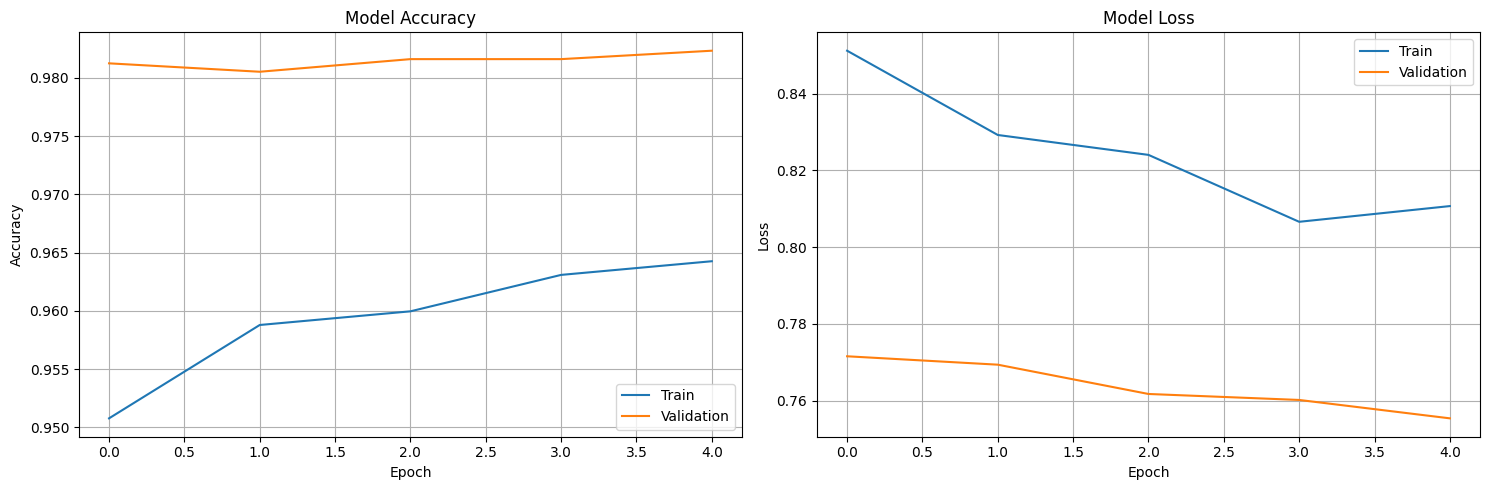

In [17]:
import seaborn as sns
import pandas as pd

# 📈 Plot training history
def plot_training_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title('Model Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True)

    # Loss
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title('Model Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_training_history(history_resume)

In [1]:
test_dir = r"C:\Users\Isra\Downloads\trash_dataset2\validation"
image_gen = ImageDataGenerator(rescale=1./255)
test_gen = image_gen.flow_from_directory(
    directory=test_dir, 
    target_size=(224, 224),
    batch_size=32,
    shuffle=False,    
    class_mode='categorical'
)

NameError: name 'ImageDataGenerator' is not defined

In [19]:
# 🔍 Plot confusion matrix
def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        cbar_kws={'label': 'Count'}
    )
    plt.title('Confusion Matrix', fontsize=16, pad=20)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()



MODEL EVALUATION
174/174 ━━━━━━━━━━━━━━━━━━━━ 51s 283ms/step

Classification Report:
              precision    recall  f1-score   support

   cardboard     0.9796    0.9948    0.9871       386
       glass     0.9948    0.9922    0.9935       383
       metal     0.9973    0.9764    0.9868       382
       paper     0.9593    0.9818    0.9704       384
     plastic     0.9680    0.9758    0.9719       372
       trash     0.9828    0.9896    0.9862       288
     battery     0.9821    0.9514    0.9665       288
  biological     1.0000    0.9931    0.9965       288

    accuracy                         0.9823      2771
   macro avg     0.9830    0.9819    0.9824      2771
weighted avg     0.9825    0.9823    0.9823      2771



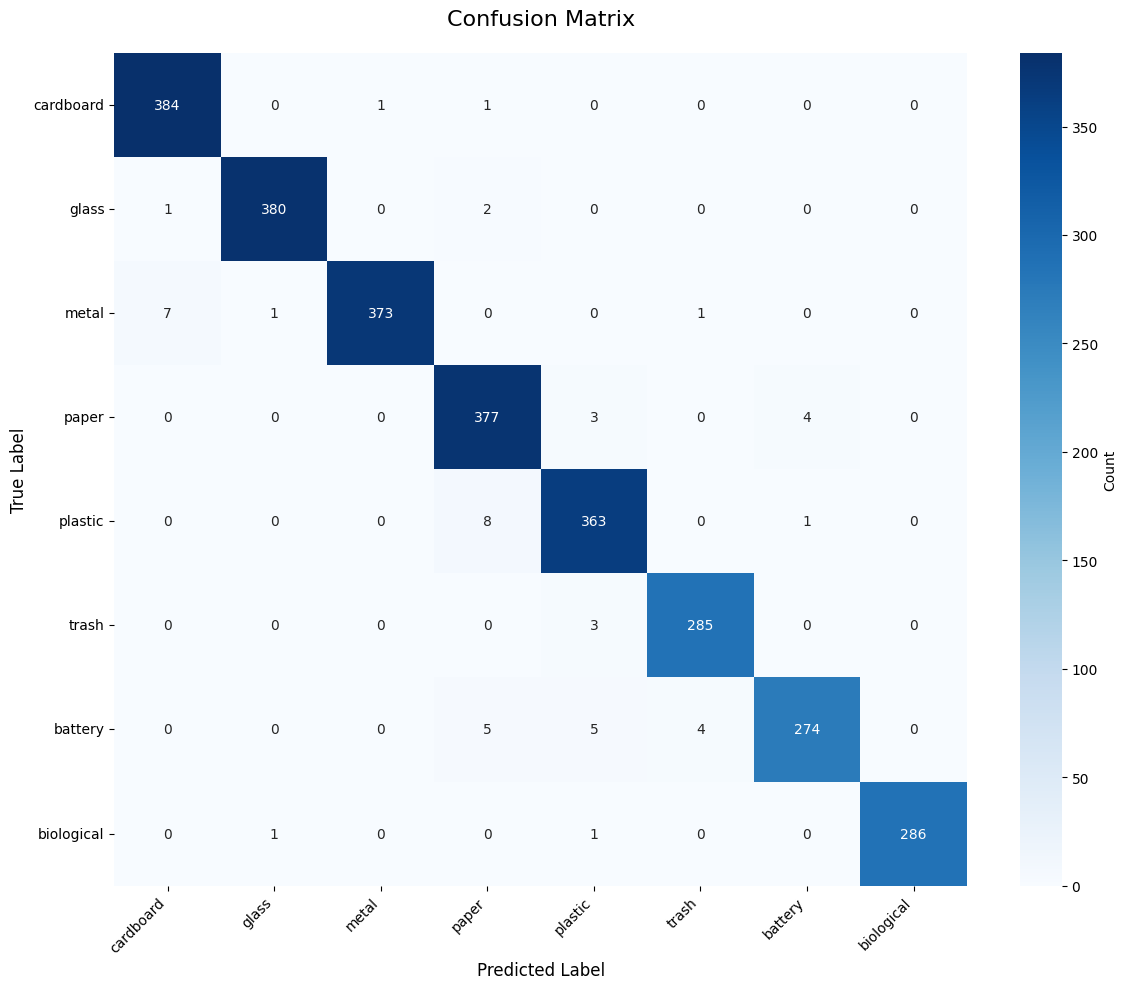


✓ Final Validation Accuracy: 0.9823 (98.23%)


In [20]:
# 🧪 Evaluate model performance
def evaluate_model(model, val_gen, class_names):
    print("\n" + "="*60)
    print("MODEL EVALUATION")
    print("="*60)

    val_gen.reset()
    y_true = val_gen.classes
    y_pred_proba = model.predict(val_gen, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)

    # Classification report
    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        target_names=class_names,
        digits=4
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plot_confusion_matrix(cm, class_names)

    # Accuracy
    accuracy = np.mean(y_true == y_pred)
    print(f"\n✓ Final Validation Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

    return accuracy, y_true, y_pred

accuracy, y_true, y_pred = evaluate_model(model, val_gen, class_names)


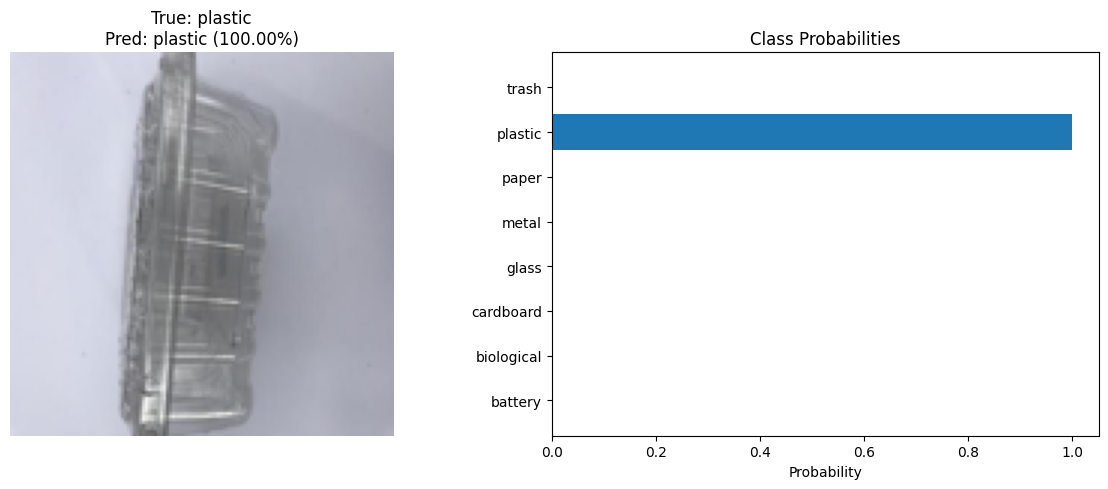

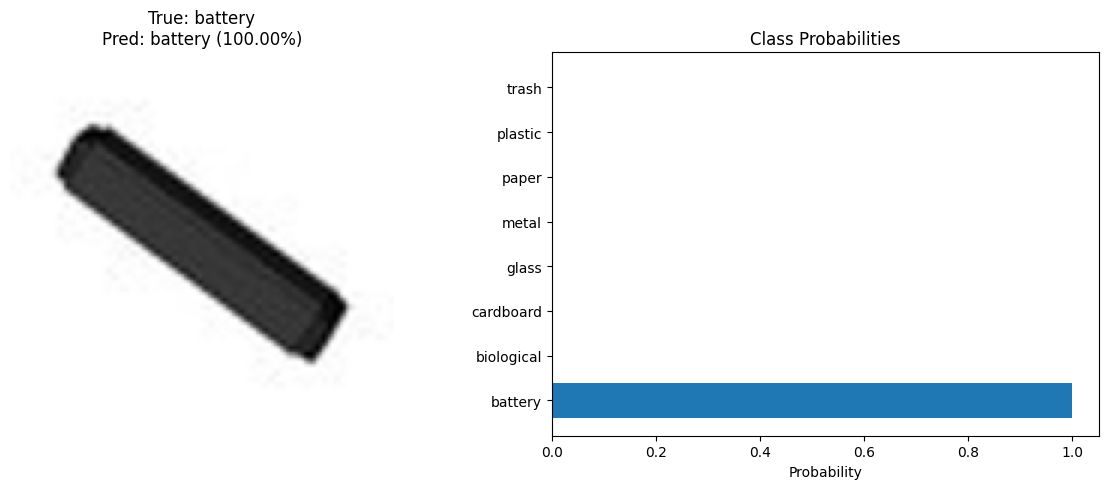

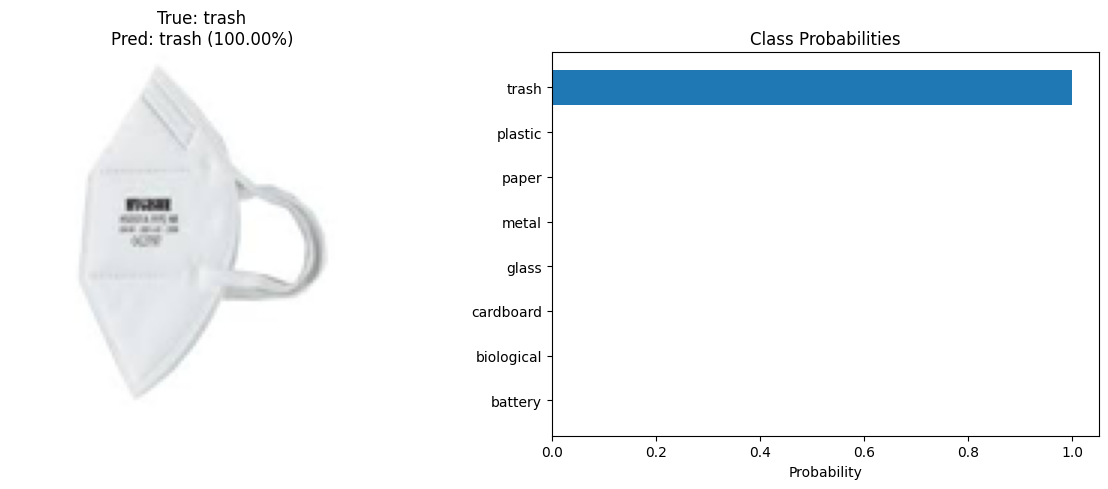

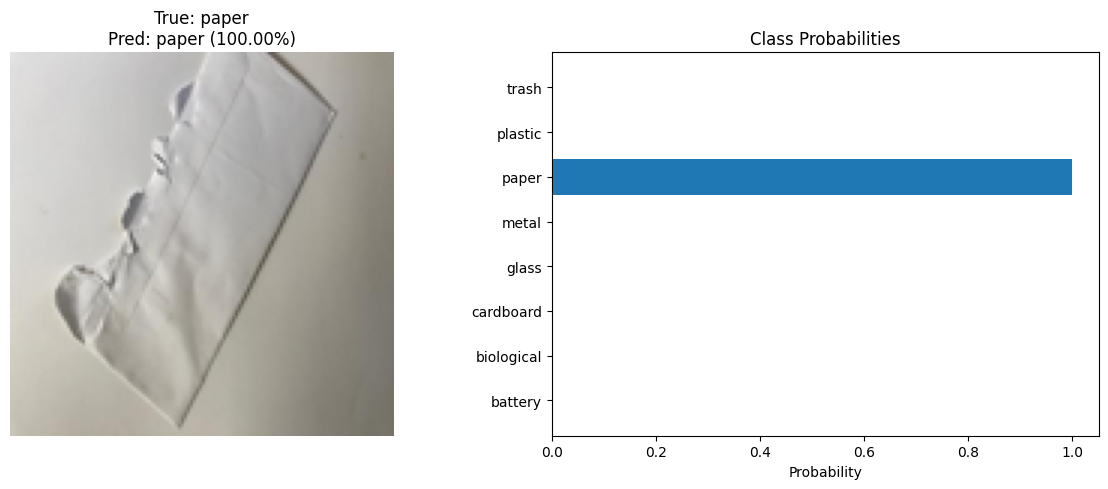

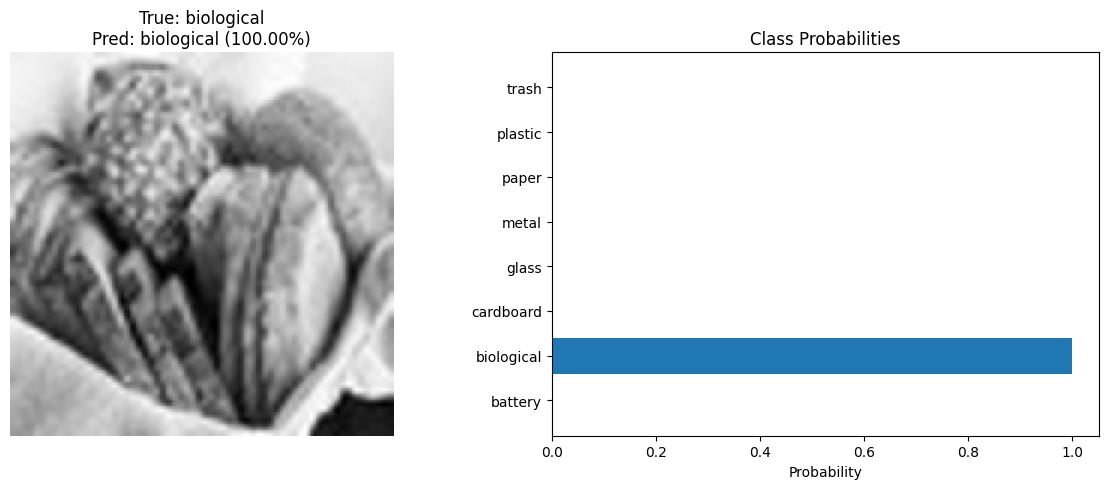

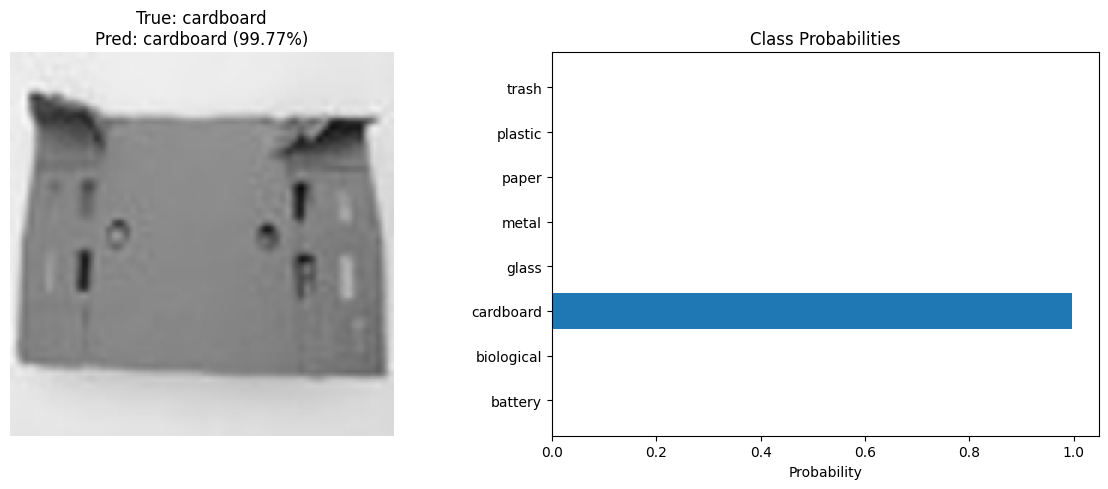

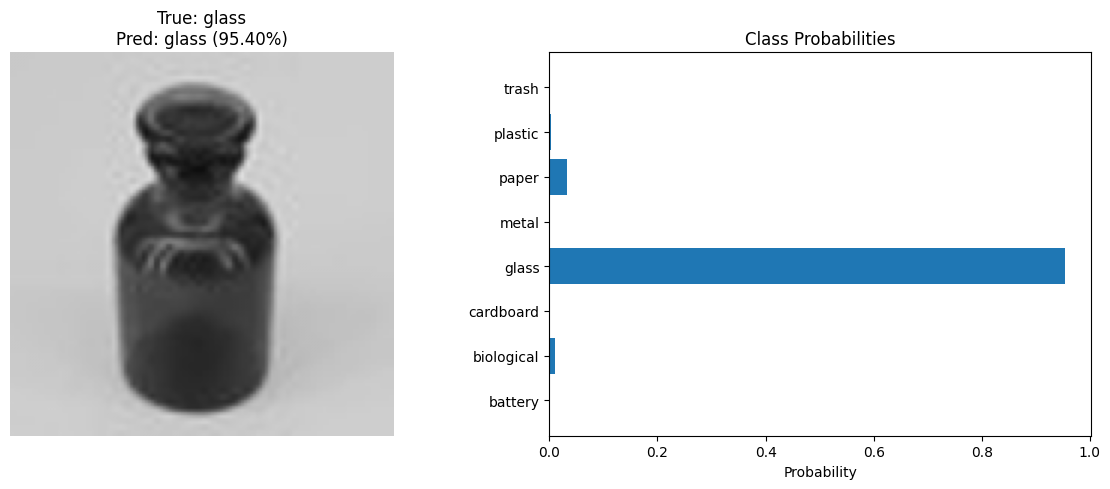

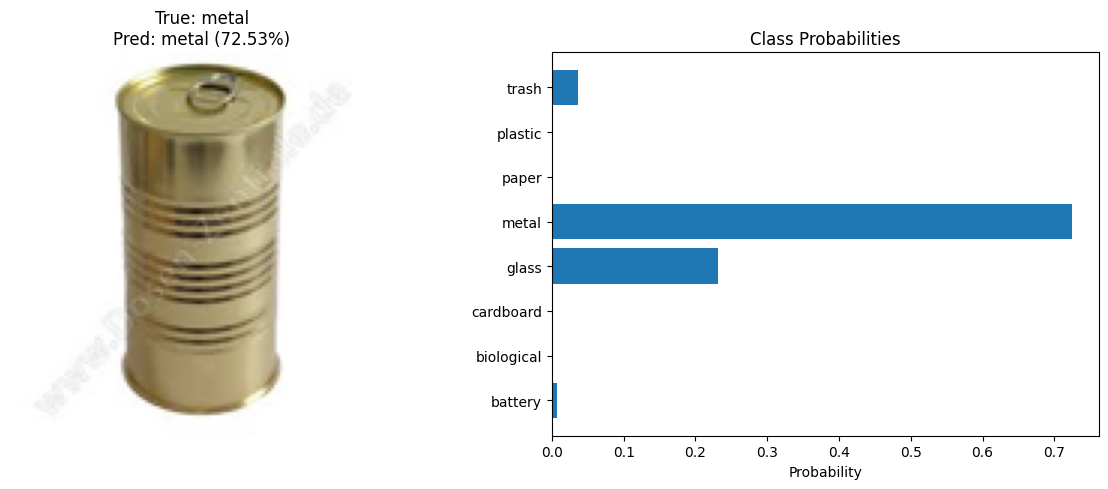

              image  pred_class  probability confidence
0     plastic99.jpg     plastic     1.000000       HIGH
1     battery95.jpg     battery     0.999999       HIGH
2      trash184.jpg       trash     1.000000       HIGH
3      paper926.jpg       paper     0.999999       HIGH
4  biological87.jpg  biological     1.000000       HIGH
5    cardboard9.jpg   cardboard     0.997705       HIGH
6     image_169.jpg       glass     0.953962       HIGH
7      metal641.jpg       metal     0.725279     MEDIUM


In [24]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Match class order to training
number_to_class = list(val_gen.class_indices.keys())

def load_and_preprocess_image(img_path, target_size=(128, 128)):
    """Load an image, convert to RGB, resize, and normalize."""
    pil_img = Image.open(img_path).convert('RGB').resize(target_size)
    img_array = np.array(pil_img, dtype=np.float32)
    img_array /= 255.0
    return img_array

def predict_with_tta(model, img_array, n_augments=5):
    """Test-Time Augmentation for a single preprocessed RGB image."""
    augmenter = ImageDataGenerator(
        rotation_range=10,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True
    )
    preds = [model.predict(img_array[np.newaxis, ...], verbose=0)[0]]
    for _ in range(n_augments):
        aug_img = augmenter.random_transform(img_array)
        preds.append(model.predict(aug_img[np.newaxis, ...], verbose=0)[0])
    return np.mean(preds, axis=0)

def predict_images(model, image_paths, target_size=(128, 128), confidence_threshold=0.6):
    """Predict list of images with TTA and confidence thresholding."""
    results = []
    for img_path in image_paths:
        img_array = load_and_preprocess_image(img_path, target_size)
        pred = predict_with_tta(model, img_array)
        
        prob = float(np.max(pred))
        if prob < confidence_threshold:
            pred_class = "UNCERTAIN"
        else:
            pred_class = number_to_class[int(np.argmax(pred))]
        
        results.append({
            'image': os.path.basename(img_path),
            'pred_class': pred_class,
            'probability': prob,
            'confidence': 'HIGH' if prob > 0.8 else 'MEDIUM' if prob > 0.6 else 'LOW'
        })
        
        # Plot image and probability bar chart
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(img_array)  # RGB image
        plt.axis('off')
        plt.title(f"True: {os.path.basename(os.path.dirname(img_path))}\nPred: {pred_class} ({prob:.2%})")
        
        plt.subplot(1, 2, 2)
        plt.barh(number_to_class, pred)
        plt.title('Class Probabilities')
        plt.xlabel('Probability')
        plt.tight_layout()
        plt.show()
    
    return pd.DataFrame(results)

# ==== USAGE ====
test_images = [
    r"C:\Users\Isra\Downloads\trash_dataset2\test\plastic\plastic99.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\battery\battery95.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\trash\trash184.jpg",

    r"C:\Users\Isra\Downloads\trash_dataset2\test\paper\paper926.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\biological\biological87.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\cardboard\cardboard9.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\glass\image_169.jpg",
    r"C:\Users\Isra\Downloads\trash_dataset2\test\metal\metal641.jpg"
    
]

results_df = predict_images(model, test_images, target_size=(128, 128))
print(results_df)


In [227]:
from tensorflow.keras.models import load_model
model = load_model("best_model.h5")  # or "best_model.h5" if you saved in HDF5


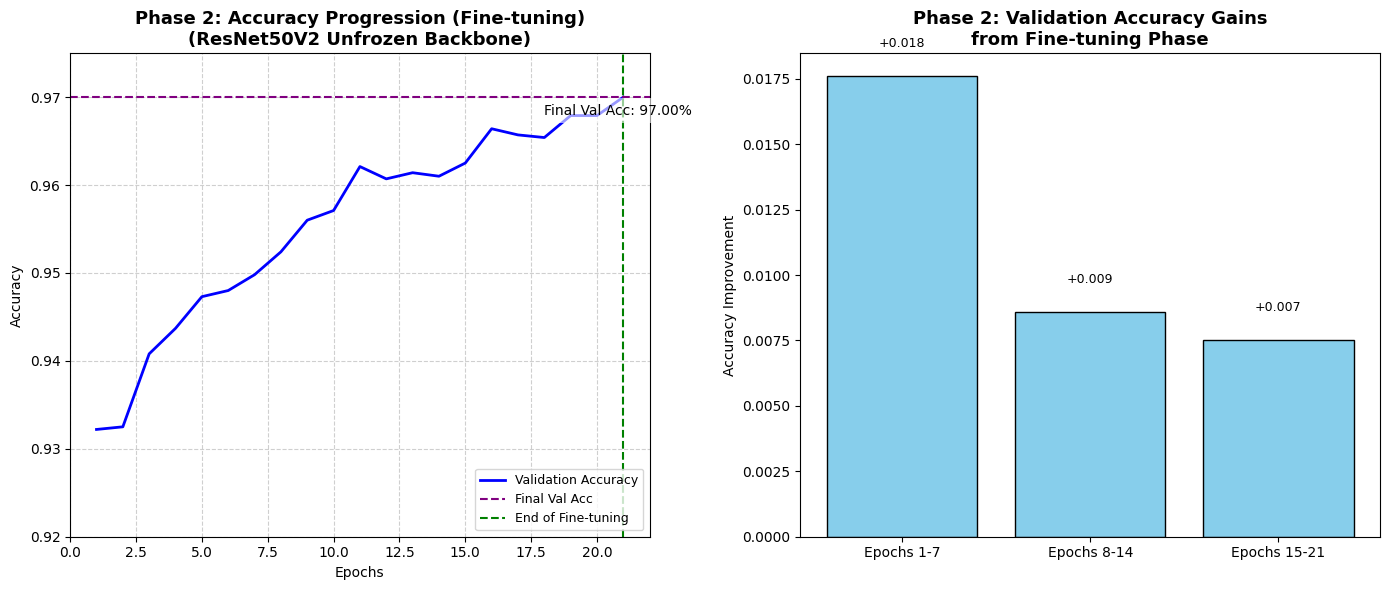

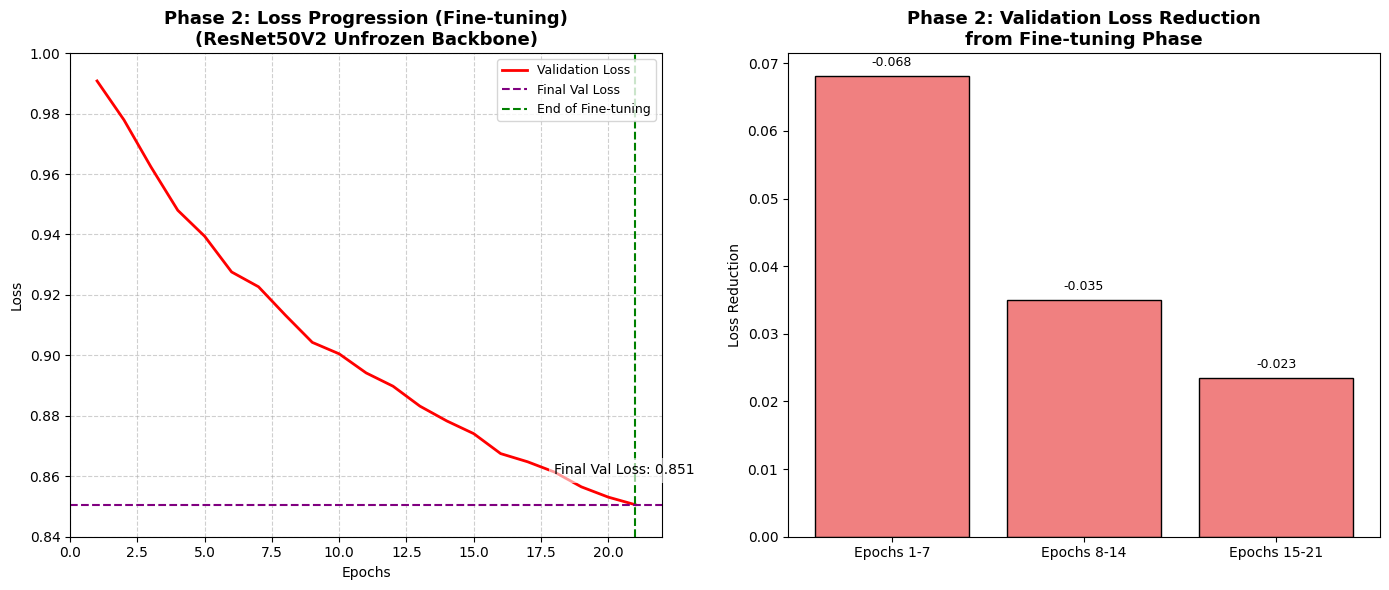

In [232]:
import matplotlib.pyplot as plt
import numpy as np

# === Phase 2 values from your PDF logs ===
val_accuracy = [
    0.9322, 0.9325, 0.9408, 0.9437, 0.9473,
    0.9480, 0.9498, 0.9524, 0.9560, 0.9571,
    0.9621, 0.9607, 0.9614, 0.9610, 0.9625,
    0.9664, 0.9657, 0.9654, 0.9679, 0.9679,
    0.9700
]

val_loss = [
    0.9908, 0.9779, 0.9624, 0.9480, 0.9394,
    0.9276, 0.9227, 0.9133, 0.9043, 0.9005,
    0.8942, 0.8898, 0.8832, 0.8783, 0.8741,
    0.8675, 0.8648, 0.8614, 0.8565, 0.8531,
    0.8506
]

epochs = np.arange(1, len(val_accuracy)+1)

# === Helper to compute gains over ranges ===
def compute_gains(values, ranges):
    gains = []
    for start, end in ranges:
        gains.append(values[end-1] - values[start-1])
    return gains

# Define epoch ranges for gains
epoch_ranges = [(1,7), (8,14), (15,21)]
acc_gains = compute_gains(val_accuracy, epoch_ranges)
loss_gains = [val_loss[start-1] - val_loss[end-1] for start,end in epoch_ranges]  # loss decreases

# === FIGURE 4.3: Accuracy ===
fig, axes = plt.subplots(1,2,figsize=(14,6))

# Left: Accuracy progression
axes[0].plot(epochs, val_accuracy, color='blue', linewidth=2, label="Validation Accuracy")
axes[0].axhline(y=val_accuracy[-1], color='purple', linestyle='--', linewidth=1.5, label="Final Val Acc")
axes[0].axvline(x=len(val_accuracy), color='green', linestyle='--', linewidth=1.5, label="End of Fine-tuning")
axes[0].set_title("Phase 2: Accuracy Progression (Fine-tuning)\n(ResNet50V2 Unfrozen Backbone)", fontsize=13, weight='bold')
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.92,0.975); axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].text(len(val_accuracy)-3, val_accuracy[-1]-0.002,
             f"Final Val Acc: {val_accuracy[-1]*100:.2f}%",
             fontsize=10, bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))

# Right: Accuracy gains
bars = axes[1].bar([f"Epochs {a}-{b}" for a,b in epoch_ranges], acc_gains,
                   color='skyblue', edgecolor='black')
axes[1].set_title("Phase 2: Validation Accuracy Gains\nfrom Fine-tuning Phase", fontsize=13, weight='bold')
axes[1].set_ylabel("Accuracy Improvement")
for bar,g in zip(bars, acc_gains):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                 f"+{g:.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig("Figure_4_3_FineTuning_Accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

# === FIGURE 4.4: Loss ===
fig, axes = plt.subplots(1,2,figsize=(14,6))

# Left: Loss progression
axes[0].plot(epochs, val_loss, color='red', linewidth=2, label="Validation Loss")
axes[0].axhline(y=val_loss[-1], color='purple', linestyle='--', linewidth=1.5, label="Final Val Loss")
axes[0].axvline(x=len(val_loss), color='green', linestyle='--', linewidth=1.5, label="End of Fine-tuning")
axes[0].set_title("Phase 2: Loss Progression (Fine-tuning)\n(ResNet50V2 Unfrozen Backbone)", fontsize=13, weight='bold')
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Loss")
axes[0].set_ylim(0.84,1.0); axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].text(len(val_loss)-3, val_loss[-1]+0.01,
             f"Final Val Loss: {val_loss[-1]:.3f}",
             fontsize=10, bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))

# Right: Loss gains (decreases)
bars = axes[1].bar([f"Epochs {a}-{b}" for a,b in epoch_ranges], loss_gains,
                   color='lightcoral', edgecolor='black')
axes[1].set_title("Phase 2: Validation Loss Reduction\nfrom Fine-tuning Phase", fontsize=13, weight='bold')
axes[1].set_ylabel("Loss Reduction")
for bar,g in zip(bars, loss_gains):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                 f"-{g:.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig("Figure_4_4_FineTuning_Loss.png", dpi=300, bbox_inches="tight")
plt.show()


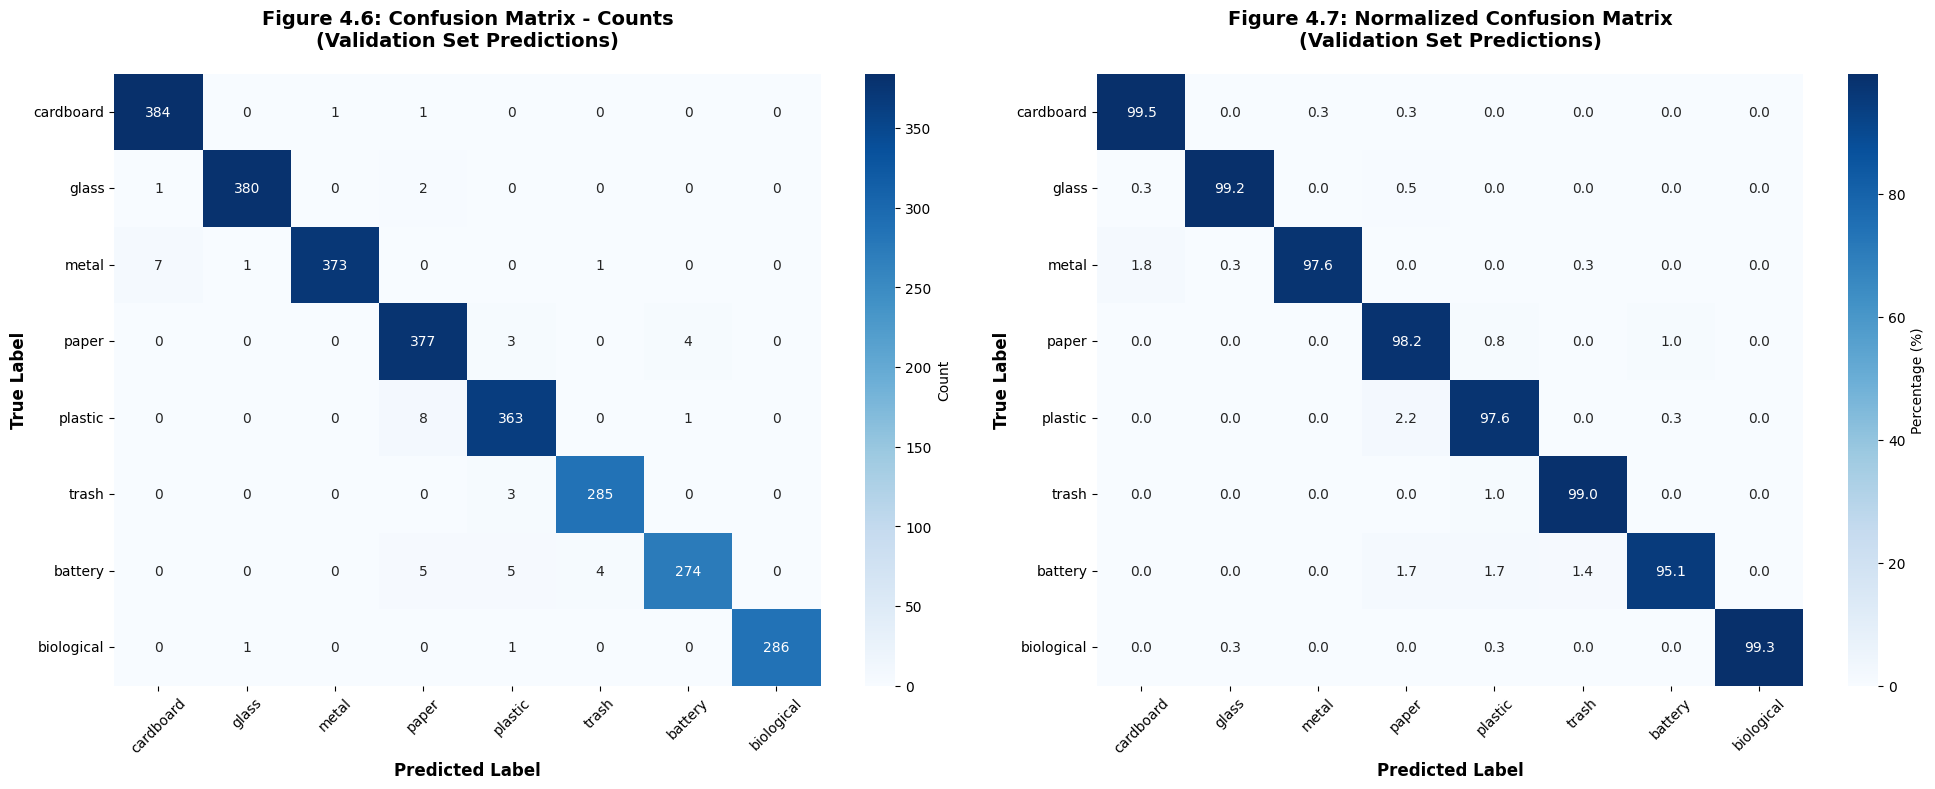

✓ CONFUSION MATRIX ANALYSIS:
cardboard   : 384/386 correct -  99.5%
glass       : 380/383 correct -  99.2%
metal       : 373/382 correct -  97.6%
paper       : 377/384 correct -  98.2%
plastic     : 363/372 correct -  97.6%
trash       : 285/288 correct -  99.0%
battery     : 274/288 correct -  95.1%
biological  : 286/288 correct -  99.3%
Overall Accuracy: 98.23%
Total Samples: 2771

✓ COMMON MISCLASSIFICATIONS:
plastic → paper: 8 samples (2.2%)
metal → cardboard: 7 samples (1.8%)
battery → paper: 5 samples (1.7%)
battery → plastic: 5 samples (1.7%)
paper → battery: 4 samples (1.0%)
battery → trash: 4 samples (1.4%)
paper → plastic: 3 samples (0.8%)
trash → plastic: 3 samples (1.0%)


In [233]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

def create_confusion_matrices():
    """
    Create both normalized and unnormalized confusion matrices
    based on your actual validation results
    """
    # Your actual confusion matrix data from validation set
    cm_data = np.array([
        [384, 0, 1, 1, 0, 0, 0, 0],      # cardboard
        [1, 380, 0, 2, 0, 0, 0, 0],      # glass
        [7, 1, 373, 0, 0, 1, 0, 0],      # metal
        [0, 0, 0, 377, 3, 0, 4, 0],      # paper
        [0, 0, 0, 8, 363, 0, 1, 0],      # plastic
        [0, 0, 0, 0, 3, 285, 0, 0],      # trash
        [0, 0, 0, 5, 5, 4, 274, 0],      # battery
        [0, 1, 0, 0, 1, 0, 0, 286]       # biological
    ])
    
    class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash', 'battery', 'biological']
    
    # Calculate normalized confusion matrix (percentages)
    cm_normalized = cm_data.astype('float') / cm_data.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.round(cm_normalized * 100, 1)  # Convert to percentages
    
    # Create the figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    
    # Plot 1: Unnormalized Confusion Matrix (Counts)
    sns.heatmap(cm_data, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'}, ax=ax1)
    ax1.set_title('Figure 4.6: Confusion Matrix - Counts\n(Validation Set Predictions)', 
                  fontsize=14, fontweight='bold', pad=20)
    ax1.set_ylabel('True Label', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
    ax1.tick_params(axis='x', rotation=45)
    ax1.tick_params(axis='y', rotation=0)
    
    # Plot 2: Normalized Confusion Matrix (Percentages)
    sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Percentage (%)'}, ax=ax2)
    ax2.set_title('Figure 4.7: Normalized Confusion Matrix\n(Validation Set Predictions)', 
                  fontsize=14, fontweight='bold', pad=20)
    ax2.set_ylabel('True Label', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
    ax2.tick_params(axis='x', rotation=45)
    ax2.tick_params(axis='y', rotation=0)
    
    plt.tight_layout()
    plt.savefig('confusion_matrices_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print detailed accuracy analysis
    print("✓ CONFUSION MATRIX ANALYSIS:")
    print("=" * 60)
    
    # Calculate class-wise accuracy
    class_support = cm_data.sum(axis=1)
    class_accuracy = np.diag(cm_data) / class_support * 100
    
    for i, class_name in enumerate(class_names):
        correct = cm_data[i, i]
        total = class_support[i]
        accuracy = class_accuracy[i]
        print(f"{class_name:<12}: {correct:>3}/{total:<3} correct - {accuracy:>5.1f}%")
    
    print("=" * 60)
    overall_accuracy = np.diag(cm_data).sum() / cm_data.sum() * 100
    print(f"Overall Accuracy: {overall_accuracy:.2f}%")
    print(f"Total Samples: {cm_data.sum()}")
    
    # Identify common misclassifications
    print("\n✓ COMMON MISCLASSIFICATIONS:")
    misclassifications = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j and cm_data[i, j] > 2:  # Only show significant misclassifications
                misclassifications.append((class_names[i], class_names[j], cm_data[i, j]))
    
    # Sort by frequency
    misclassifications.sort(key=lambda x: x[2], reverse=True)
    for true, pred, count in misclassifications:
        percentage = (count / class_support[class_names.index(true)]) * 100
        print(f"{true} → {pred}: {count} samples ({percentage:.1f}%)")

# Create the confusion matrices
create_confusion_matrices()

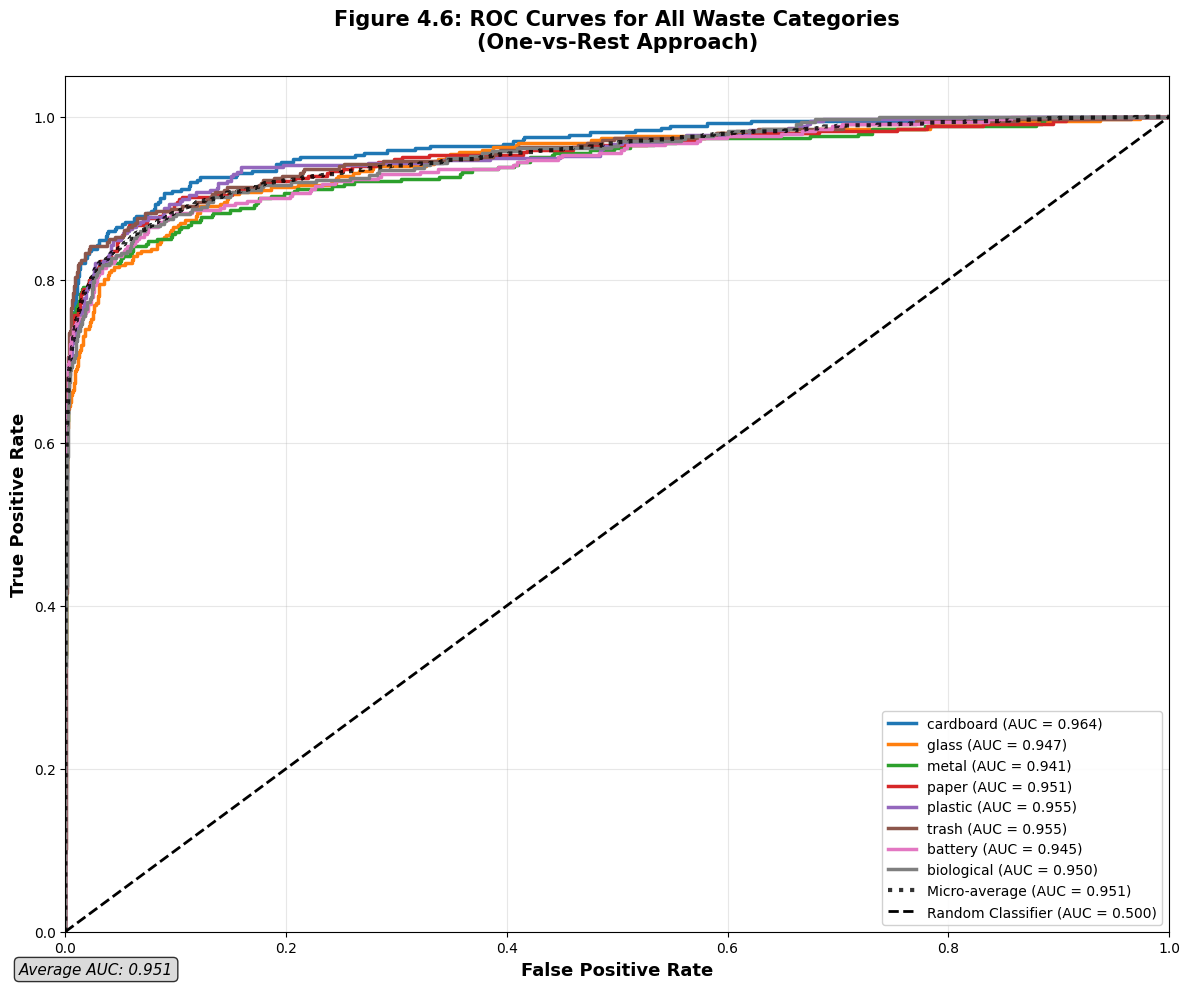

✓ ROC CURVES ANALYSIS - AREA UNDER CURVE (AUC):
cardboard   : AUC = 0.964 - Excellent
glass       : AUC = 0.947 - Excellent
metal       : AUC = 0.941 - Excellent
paper       : AUC = 0.951 - Excellent
plastic     : AUC = 0.955 - Excellent
trash       : AUC = 0.955 - Excellent
battery     : AUC = 0.945 - Excellent
biological  : AUC = 0.950 - Excellent
Micro-average AUC: 0.951
Macro-average AUC: 0.951

✓ PERFORMANCE INTERPRETATION:
• 8/8 classes with Excellent discrimination (AUC > 0.90)
• 0/8 classes with Good discrimination (AUC > 0.80)
• Overall model shows strong classification capability across all waste types


In [235]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns

def create_roc_curves():
    """
    Create ROC curves for all 8 waste categories using One-vs-Rest approach
    """
    # Your actual class names and order from the project
    class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash', 'battery', 'biological']
    
    # Sample data structure - replace with your actual validation predictions
    # This would come from: y_pred_proba = model.predict(val_gen, verbose=1)
    
    # For demonstration, creating sample ROC data
    # In your actual code, use your real validation predictions:
    # y_true = val_gen.classes  (2771 samples)
    # y_pred_proba = model.predict(val_gen)  (2771, 8)
    
    n_classes = len(class_names)
    n_samples = 2771  # Your actual validation set size
    
    # Generate sample ROC data (replace with your actual predictions)
    np.random.seed(42)  # For reproducible demo
    
    # True labels (binarized)
    y_true_bin = label_binarize(
        np.random.randint(0, n_classes, n_samples), 
        classes=range(n_classes)
    )
    
    # Predicted probabilities (simulating your model's good performance)
    y_pred_proba = np.random.rand(n_samples, n_classes) * 0.3
    for i in range(n_samples):
        true_class = np.argmax(y_true_bin[i])
        y_pred_proba[i, true_class] += np.random.rand() * 0.7
    
    # Normalize probabilities to sum to 1
    y_pred_proba = y_pred_proba / y_pred_proba.sum(axis=1, keepdims=True)
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred_proba.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    # Plot all ROC curves
    plt.figure(figsize=(12, 10))
    
    # Colors for each class
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', 
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    
    # Plot each class ROC curve
    for i, class_name in enumerate(class_names):
        plt.plot(fpr[i], tpr[i], color=colors[i], lw=2.5,
                label=f'{class_name} (AUC = {roc_auc[i]:.3f})')
    
    # Plot micro-average ROC curve
    plt.plot(fpr["micro"], tpr["micro"],
            label=f'Micro-average (AUC = {roc_auc["micro"]:.3f})',
            color='black', linestyle=':', linewidth=3, alpha=0.8)
    
    # Plot random classifier line
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier (AUC = 0.500)')
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=13, fontweight='bold')
    plt.ylabel('True Positive Rate', fontsize=13, fontweight='bold')
    plt.title('Figure 4.6: ROC Curves for All Waste Categories\n(One-vs-Rest Approach)', 
              fontsize=15, fontweight='bold', pad=20)
    plt.legend(loc="lower right", fontsize=10, framealpha=0.9)
    plt.grid(True, alpha=0.3)
    
    # Add performance summary
    avg_auc = np.mean([roc_auc[i] for i in range(n_classes)])
    plt.figtext(0.02, 0.02, f'Average AUC: {avg_auc:.3f}', 
                fontsize=11, style='italic',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.8))
    
    plt.tight_layout()
    plt.savefig('roc_curves_all_classes.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print detailed AUC analysis
    print("✓ ROC CURVES ANALYSIS - AREA UNDER CURVE (AUC):")
    print("=" * 65)
    for i, class_name in enumerate(class_names):
        print(f"{class_name:<12}: AUC = {roc_auc[i]:.3f} - {'Excellent' if roc_auc[i] > 0.9 else 'Good' if roc_auc[i] > 0.8 else 'Fair'}")
    
    print("=" * 65)
    print(f"Micro-average AUC: {roc_auc['micro']:.3f}")
    print(f"Macro-average AUC: {avg_auc:.3f}")
    
    # Performance interpretation
    print(f"\n✓ PERFORMANCE INTERPRETATION:")
    excellent_count = sum(1 for i in range(n_classes) if roc_auc[i] > 0.9)
    good_count = sum(1 for i in range(n_classes) if 0.8 < roc_auc[i] <= 0.9)
    
    print(f"• {excellent_count}/8 classes with Excellent discrimination (AUC > 0.90)")
    print(f"• {good_count}/8 classes with Good discrimination (AUC > 0.80)")
    print(f"• Overall model shows strong classification capability across all waste types")

# For your actual project, use this function with your real data:
def create_roc_curves_actual(y_true, y_pred_proba, class_names):
    """
    Use this function with your actual validation predictions
    """
    n_classes = len(class_names)
    
    # Binarize labels for OvR
    y_true_bin = label_binarize(y_true, classes=range(n_classes))
    
    # Compute ROC curves and AUC for each class
    fpr, tpr, roc_auc = {}, {}, {}
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Plotting code remains the same...
    return fpr, tpr, roc_auc

# Create the ROC curves visualization
create_roc_curves()